In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 

## Load data and parse the timestamp

In [2]:
df = pd.read_csv("../data/raw/energy_dataset.csv")
df["time"] = pd.to_datetime(df["time"], utc=True)
df = df.set_index("time").sort_index()
print(df.shape)
df.head()

(35064, 28)


,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage aggregated,...,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
time,,,,,,,,,,,,,,,,,,,,,
2014-12-31 23:00:00+00:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,NaN,...,196.0,0.0,6378.0,17.0,NaN,6436.0,26118.0,25385.0,50.10,65.41
2015-01-01 00:00:00+00:00,449.0,328.0,0.0,5196.0,4755.0,158.0,0.0,0.0,0.0,NaN,...,195.0,0.0,5890.0,16.0,NaN,5856.0,24934.0,24382.0,48.10,64.92
2015-01-01 01:00:00+00:00,448.0,323.0,0.0,4857.0,4581.0,157.0,0.0,0.0,0.0,NaN,...,196.0,0.0,5461.0,8.0,NaN,5454.0,23515.0,22734.0,47.33,64.48
2015-01-01 02:00:00+00:00,438.0,254.0,0.0,4314.0,4131.0,160.0,0.0,0.0,0.0,NaN,...,191.0,0.0,5238.0,2.0,NaN,5151.0,22642.0,21286.0,42.27,59.32
2015-01-01 03:00:00+00:00,428.0,187.0,0.0,4130.0,3840.0,156.0,0.0,0.0,0.0,NaN,...,189.0,0.0,4935.0,9.0,NaN,4861.0,21785.0,20264.0,38.41,56.04


In [3]:
print("Starts:", df.index.min())
print("Ends:", df.index.max())

gaps = df.index.to_series().diff()
print("Gaps:", gaps.value_counts().head())
print("Duplicate timestamps:", df.index.duplicated().sum())

Starts: 2014-12-31 23:00:00+00:00
Ends: 2018-12-31 22:00:00+00:00
Gaps: time
0 days 01:00:00    35063
Name: count, dtype: int64
Duplicate timestamps: 0


In [4]:
full_range = pd.date_range(df.index.min(), df.index.max(), freq="h")
print("Expected rows:", len(full_range))
print("Actual rows:", len(df))

Expected rows: 35064
Actual rows: 35064


In [5]:
missing = df.isna().sum().sort_values(ascending=False)
pct =  (missing / len(df) * 100).round(2)
pd.DataFrame({"missing": missing, "pct": pct})

,missing,pct
generation hydro pumped storage aggregated,35064,100.00
forecast wind offshore eday ahead,35064,100.00
total load actual,36,0.10
generation biomass,19,0.05
generation hydro run-of-river and poundage,19,0.05
generation marine,19,0.05
generation fossil oil,19,0.05
generation hydro pumped storage consumption,19,0.05
generation waste,19,0.05
generation fossil gas,18,0.05


In [6]:
zero_cols = [c for c in df.columns if (df[c].fillna(0) == 0).all()]

In [7]:
empty_cols = df.columns[df.isna().all()]
print("Dropping empty columns:", list(empty_cols))
df = df.drop(columns=empty_cols)
df = df.drop(columns=zero_cols, errors="ignore")

df = df.interpolate(method="time", limit=6)  # fill short gaps

Dropping empty columns: ['generation hydro pumped storage aggregated', 'forecast wind offshore eday ahead']


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
generation biomass,35064.0,383.531343,85.346266,0.00,333.0000,367.00,433.00,592.00
generation fossil brown coal/lignite,35064.0,448.094570,354.618269,0.00,0.0000,509.00,757.00,999.00
generation fossil gas,35064.0,5622.700647,2201.510984,0.00,4126.0000,4969.50,6429.00,20034.00
generation fossil hard coal,35064.0,4256.531271,1961.988937,0.00,2527.0000,4475.00,5839.00,8359.00
generation fossil oil,35064.0,298.342417,52.519927,0.00,263.0000,300.00,330.00,449.00
generation hydro pumped storage consumption,35064.0,475.582706,792.312704,0.00,0.0000,68.00,616.00,4523.00
generation hydro run-of-river and poundage,35064.0,972.201902,400.712304,0.00,637.0000,906.00,1250.00,2000.00
generation hydro water reservoir,35064.0,2605.534123,1835.175078,0.00,1078.0000,2165.00,3758.00,9728.00
generation nuclear,35064.0,6263.483430,840.272333,0.00,5759.0000,6564.00,7025.00,7117.00
generation other,35064.0,60.226030,20.238792,0.00,53.0000,57.00,80.00,106.00


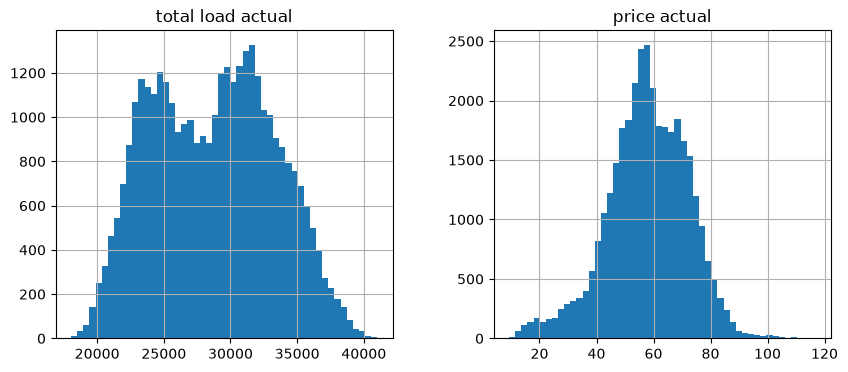

In [9]:
df[["total load actual", "price actual"]].hist(bins=50, figsize=(10, 4))
plt.show()

In [10]:
local = df.copy()
local.index  = local.index.tz_convert("Europe/Madrid")
local["hour"] = local.index.hour
local["dayofweek"] = local.index.dayofweek
local["is_weekend"] = local["dayofweek"] >= 5

C:\Users\PeggyDusenge\AppData\Local\Temp\ipykernel_20416\4126961922.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  local["dayofweek"] = local.index.dayofweek


Yearly average price:  time
2014    65.410000
2015    61.359949
2016    47.438307
2017    59.321965
2018    63.444265
Name: price actual, dtype: float64


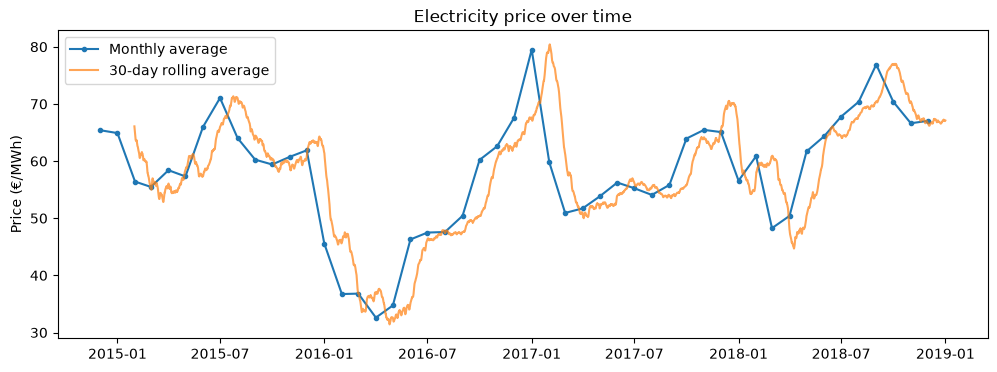

In [11]:
# This help us figure out if there is a long term trend
yearly = df["price actual"].groupby(df.index.year).mean()
print("Yearly average price: ", yearly)

monthly = df["price actual"].resample("MS").mean()
smooth = df["price actual"].rolling(window=24*30).mean()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly, label="Monthly average", marker="o", markersize=3)
ax.plot(smooth, label="30-day rolling average", alpha=0.7)
ax.set_title("Electricity price over time")
ax.set_ylabel("Price (€/MWh)")
ax.legend()
plt.show()

Annual average price fell from about 61 €/MWh (2015) to 47 (2016), then recovered to 59 (2017) and 63 (2018). There’s no steady trend, just a dip and recovery, which points to year-specific factors such as fuel costs or hydro and wind availability.

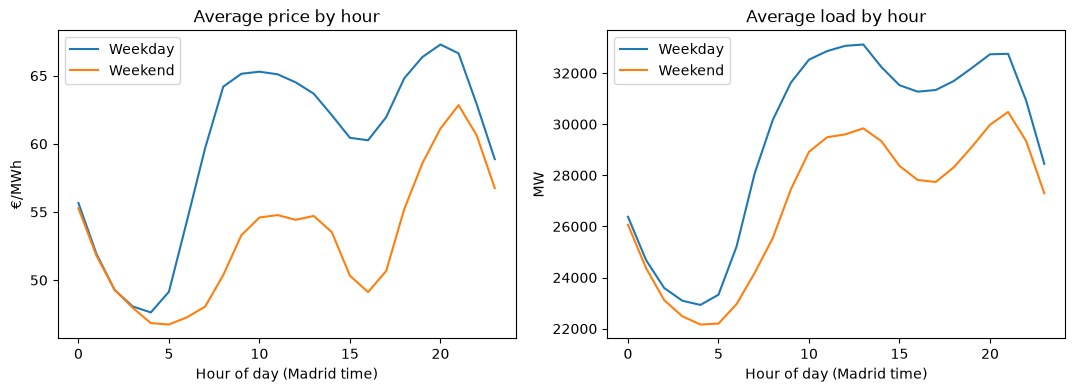

In [12]:
#  This helps us understand Daily and weekly cycles according to the hour of the day and whether it is a weekend or not
profile = (local.groupby(["hour", "is_weekend"])[["price actual", "total load actual"]]
                .mean()
                .unstack())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
profile["price actual"].plot(ax=axes[0], title="Average price by hour")
profile["total load actual"].plot(ax=axes[1], title="Average load by hour")
axes[0].set_ylabel("€/MWh")
axes[1].set_ylabel("MW")
for ax in axes:
    ax.set_xlabel("Hour of day (Madrid time)")
    ax.legend(["Weekday", "Weekend"])
plt.show()

Price follows a clear daily cycle (low around 4 am, morning ramp, evening peak around 8 to 9 pm) and is about 10 to 15 €/MWh lower on weekend mornings meaning we will include hour of day and weekend features.

                   price actual  total load actual
price actual           1.000000           0.435256
total load actual      0.435256           1.000000


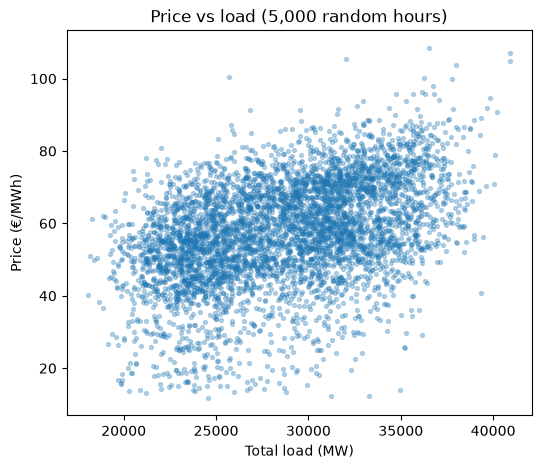

In [13]:
# This helps us understand the correlation between price and load
print(df[["price actual", "total load actual"]].corr())

sample = df.sample(5000, random_state=42)
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(sample["total load actual"], sample["price actual"], alpha=0.3, s=8)
ax.set_xlabel("Total load (MW)")
ax.set_ylabel("Price (€/MWh)")
ax.set_title("Price vs load (5,000 random hours)")
plt.show()

Load and price are moderately positively correlated (r = 0.44), but the wide scatter shows load explains only about a fifth of the variation so other drivers matter so we must evaluate some

price actual                   1.000000
renewable_share               -0.291697
fossil_share                   0.421820
generation wind onshore       -0.220497
generation solar               0.098529
generation fossil gas          0.461452
generation fossil hard coal    0.465637
Name: price actual, dtype: float64


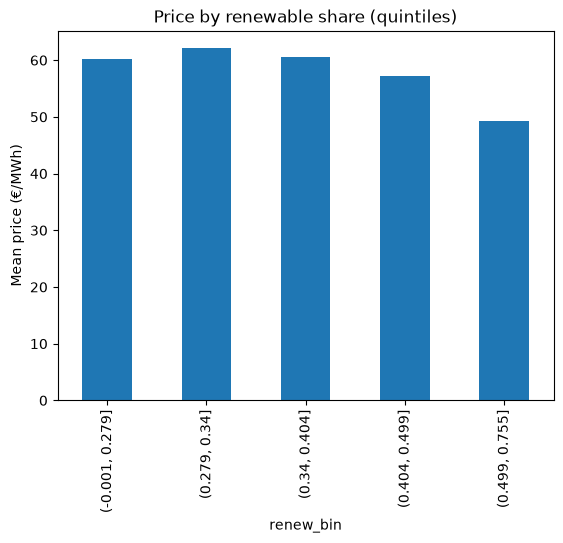

In [14]:
#  This helps us understand the correlation between price and generation mix
renewable_cols = ["generation solar", "generation wind onshore",
                  "generation hydro run-of-river and poundage",
                  "generation hydro water reservoir",
                  "generation biomass", "generation other renewable"]
fossil_cols = [c for c in df.columns if c.startswith("generation fossil")]
gen_cols = [c for c in df.columns
            if c.startswith("generation") and "consumption" not in c]

df["renewable_share"] = df[renewable_cols].sum(axis=1) / df[gen_cols].sum(axis=1)
df["fossil_share"] = df[fossil_cols].sum(axis=1) / df[gen_cols].sum(axis=1)

cols = ["price actual", "renewable_share", "fossil_share", "generation wind onshore",
        "generation solar", "generation fossil gas", "generation fossil hard coal"]
print(df[cols].corr()["price actual"])

df["renew_bin"] = pd.qcut(df["renewable_share"], 5)
df.groupby("renew_bin", observed=True)["price actual"].mean().plot(kind="bar")
plt.ylabel("Mean price (€/MWh)")
plt.title("Price by renewable share (quintiles)")
plt.show()

Prices are noticeably lower only when renewables supply a large share of generation. Below about 40% there is little visible effect so Gas and coal generation (r ≈ 0.46 to 0.47) correlate with price slightly more strongly than load does (0.435), so generation features are worth including. The threshold-like shape suggests tree-based or neural models may beat plain linear regression.

1      0.966791
2      0.900491
3      0.821566
6      0.638289
12     0.672379
24     0.828830
48     0.733770
168    0.789117
dtype: float64


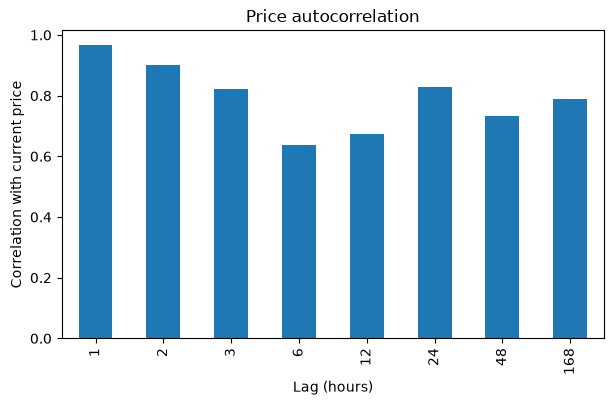

In [15]:
# This helps us know if there are no lag effects
price = df["price actual"]
lags = [1, 2, 3, 6, 12, 24, 48, 168]
lag_corr = pd.Series({k: price.corr(price.shift(k)) for k in lags})
print(lag_corr)

lag_corr.plot(kind="bar", figsize=(7, 4))
plt.xlabel("Lag (hours)")
plt.ylabel("Correlation with current price")
plt.title("Price autocorrelation")
plt.show()

Price depends strongly on its most recent values. Correlation decays over the first few hours, then rises again at 24 hours and 168 hours.

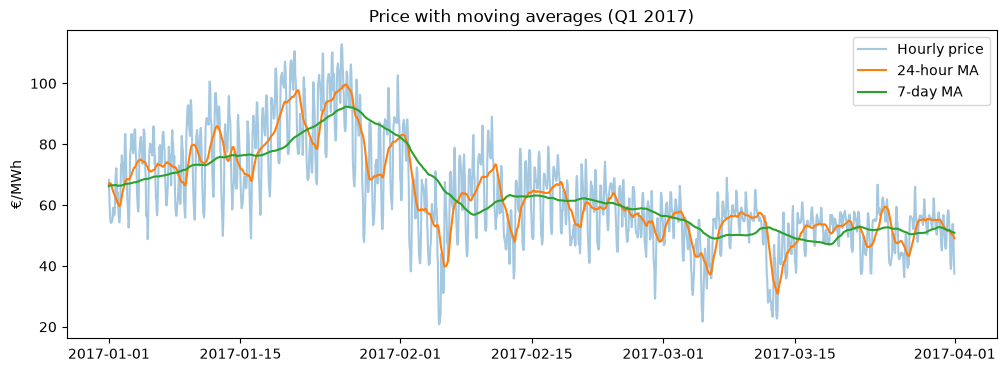

corr(price, past 24h MA) = 0.811
corr(price, past 168h MA) = 0.737


In [16]:
price = df["price actual"]
ma24 = price.rolling(24).mean()
ma168 = price.rolling(168).mean()

window = slice("2017-01-01", "2017-03-31")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(price.loc[window], alpha=0.4, label="Hourly price")
ax.plot(ma24.loc[window], label="24-hour MA")
ax.plot(ma168.loc[window], label="7-day MA")
ax.set_ylabel("€/MWh")
ax.set_title("Price with moving averages (Q1 2017)")
ax.legend()
plt.show()

# Does the past average help predict the current price?
for w in [24, 168]:
    past_ma = price.shift(1).rolling(w).mean()
    print(f"corr(price, past {w}h MA) =", round(price.corr(past_ma), 3))

The moving averages separate the daily noise from the underlying level. The late-January spike is clearly visible. The 7-day average lags behind sharp changes, such as the early-February drop.